# Kymograph Lookup and Gene types

In [10]:
import trenchripper as tr

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy as sp
import pickle as pkl

%matplotlib inline

import dask.dataframe as dd

In [64]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="01:00:00",#"02:00:00",#"04:00:00",
    local=False,
    n_workers=100,#200,
    n_workers_min=20,#100,
    memory= "16GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

50m
01:00:00


In [2]:
print(1)

1


In [86]:
dask_controller.shutdown()

Done.


2025-06-08 18:34:30,523 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [11]:
basepath_8 = '/n/scratch/groups/hms/sysbio/paulsson/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/2025-06-03_lLAG8_'
basepath_10 = '/n/scratch/groups/hms/sysbio/paulsson/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG10_ExpNum-Fixed/2025-06-03_lLAG10_'

headpaths = {0: '/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/Growth_Division/',
             1: '/home/lag36/scratch/lag36/2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed_Pipeline-Run-2-2025-05-14/Growth_Division/',
             3: '/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Growth_Division/'}

In [3]:
# path_kymograph_phenotype_8_exp_0 = '/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1_Pipeline-Run-2-2025-05-14/Growth_Division/kymograph/metadata'
# path_kymograph_phenotype_8_exp_3 = '/home/lag36/scratch/lag36/2025-03-26_lLAG8-MBM-37C-Run-09_3-Fids_Auto-Switch/Growth_Division/kymograph/metadata'

# cell_cycle_df_ss = dd.read_parquet(basepath+"Steady_State_Cell_Cycle_df/", engine="pyarrow",calculate_divisions=True)
# cell_cycle_df_preinduction = dd.read_parquet(basepath+"Preinduction_Cell_Cycle_df/", engine="pyarrow",calculate_divisions=True)

# timepoints_df_ss = dd.read_parquet(basepath+"Steady_State_Timepoints_df/", engine="pyarrow",calculate_divisions=True)
# timepoints_df_preinduction = dd.read_parquet(basepath+"Preinduction_Timepoints_df/", engine="pyarrow",calculate_divisions=True)

# growth_df_ss = dd.read_parquet(basepath+"Steady_State_Growth_df/", engine="pyarrow",calculate_divisions=True)
# growth_df_preinduction = dd.read_parquet(basepath+"Preinduction_Growth_df/", engine="pyarrow",calculate_divisions=True)

In [12]:
cols_to_keep_lookup = ['phenotype trenchid', 'File Index', 'File Trench Index', 'trenchid', 'Barcode', 'barcode', 'barcodeid','sgRNA',
       'Closest Hamming Distance', 'opLAG1_id', 'locus_tag', 'offset', 'Gene',
       'sgRNA Sequence', 'Target Sequence', 'Category', 'Predicted_Efficacy',
       'TargetID', 'barcode', 'barcodeid', 'Experiment #']

df_bar = dd.read_parquet(basepath_10+'Final_Barcodes_df_Merged/',
                        engine="pyarrow",calculate_divisions=True,
                        columns=cols_to_keep_lookup)

                        
df_bar_per_trench = (df_bar
                    .reset_index()
                    .groupby('Multi-Experiment Phenotype Trenchid')
                    .first()
                    .compute()
)

KeyboardInterrupt: 

In [ ]:
# df_bar_per_trench.to_pickle(basepath_10+'df_bar_per_trench.pkl')

In [13]:
df_bar_per_trench_8 = pd.read_pickle(basepath_8+'df_bar_per_trench.pkl')
df_bar_per_trench_10 = pd.read_pickle(basepath_10+'df_bar_per_trench.pkl')

In [77]:
# # Say I want a given opLAG1_id
# df_bar_per_trench = df_bar_per_trench_10
# cols_to_display = ['opLAG1_id', 'phenotype trenchid', 'Experiment #', 'File Index', 'File Trench Index', 'Gene', 'Category', 'Predicted_Efficacy']
# df_bar_per_trench.loc[df_bar_per_trench['Gene']=='flgM', cols_to_display]

In [14]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

def plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap = "gray"):
    file_path = headpath + subfolder + "/" + prefix+"_" + str(kymo_index) + ".hdf5"
    # print(file_path)
    with h5py.File(file_path, "r") as infile:
        # print(infile['mCherry'].shape)
        # indices = list(range(0, 1, 1))

        for ch in channels:
            img = infile[ch][trench_index][indices[0]]
            for ind in indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            _= plt.figure(figsize=(10,5))
            _ = plt.imshow(img, cmap=cmap, aspect=1)
            # Do not show axes
            _ = plt.axis('off')
            # Annotate kymo and trench index
            # _= plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
            _=plt.show()
            _=plt.close()

indices = np.arange(0, 67)
# Create a function to update the plot
def update_plot(trench_index, kymo_index):
    # y = np.sin(frequency * x)
    _ = plt.clf()  # Clear the previous plot
    channels = ["mCherry"]
    plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap='gray')
    _ = plt.show()
    
    # channels = ["data"]
    # plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "fluorsegmentation", prefix="segmentation", cmap="jet")
    # _ = plt.show()

# Create an interactive slider widget
trench_index_slider = widgets.IntSlider(min=0, max=149, step=1, value=0)
kymo_index_slider = widgets.IntSlider(min=0, max=500, step=1, value=0)

In [6]:
df_bar_per_trench = df_bar_per_trench_8

In [7]:
cols = ['opLAG1_id', 'Experiment #','File Index', 'File Trench Index', 'Gene', 'Category', 'Predicted_Efficacy']
opLAG1_id = 173.0
df_bar_per_trench.loc[df_bar_per_trench['opLAG1_id'] == opLAG1_id, cols].head(5)

,opLAG1_id,Experiment #,File Index,File Trench Index,Gene,Category,Predicted_Efficacy
Multi-Experiment Phenotype Trenchid,,,,,,,
7010,173.0,0,43,1,holB,essential,1.0
208665,173.0,0,1280,25,holB,essential,1.0
281090,173.0,0,1724,78,holB,essential,1.0
294077,173.0,0,1804,25,holB,essential,1.0
307041,173.0,0,1883,112,holB,essential,1.0


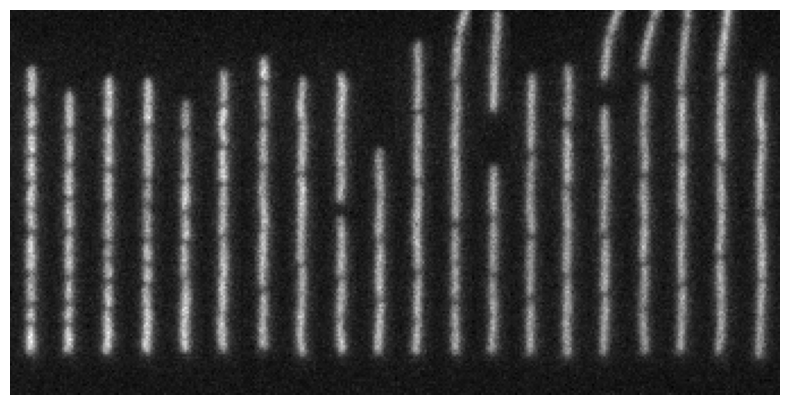

In [93]:
# ctsR example (nonessentials)
channels = ['mCherry']
experiment_number = 1
file_index = 790
file_trench_index = 59
time_indices = np.arange(7, 67, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

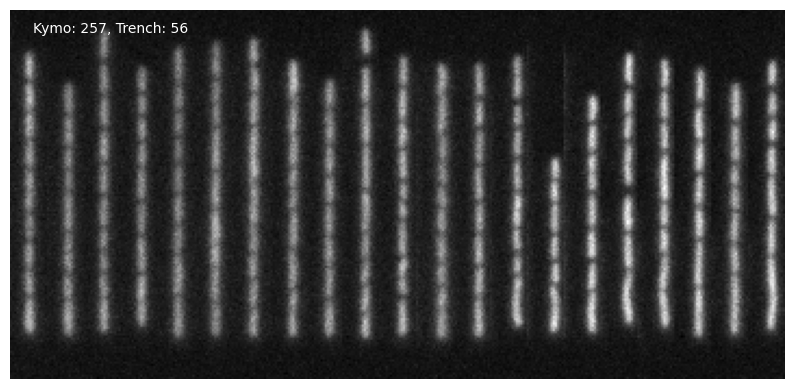

In [83]:
# rnjA example
channels = ['mCherry']
experiment_number = 0
file_index = 257
file_trench_index = 56
time_indices = np.arange(0, 61, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

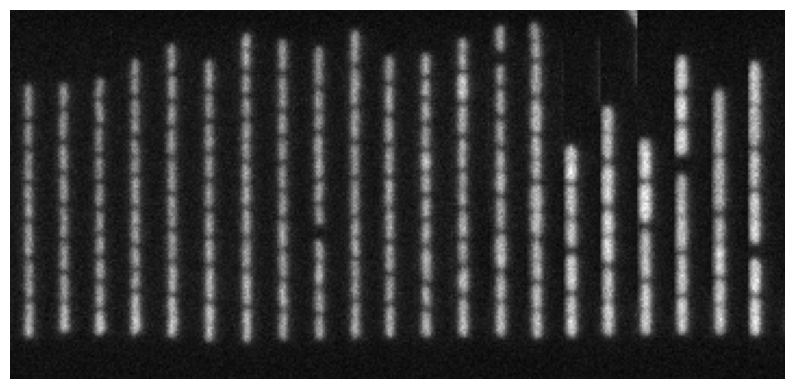

In [94]:
# murG example
channels = ['mCherry']
experiment_number = 0
file_index = 412
file_trench_index = 10
time_indices = np.arange(0, 61, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

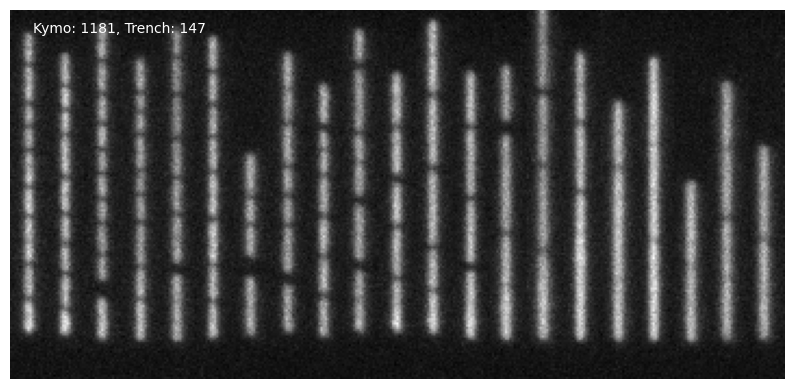

In [46]:
# Div1C example
channels = ['mCherry']
experiment_number = 0
file_index = 1181
file_trench_index = 147
time_indices = np.arange(0, 61, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

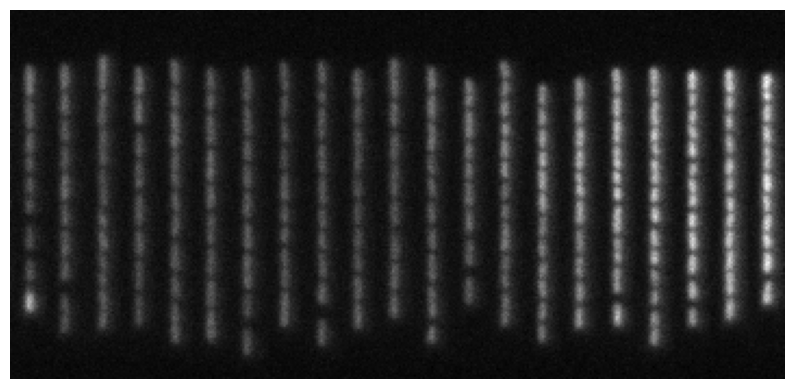

In [95]:
# ilvD example
channels = ['mCherry']
experiment_number = 0
file_index = 171
file_trench_index = 6
time_indices = np.arange(0, 61, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

In [ ]:
# Use the interact function to connect the slider to the update_plot function
# interact(update_plot, trench_index=trench_index_slider, kymo_index=kymo_index_slider)# kymo_index=kymo_index_slider)

In [ ]:
cols = ['opLAG1_id', 'Experiment #','File Index', 'File Trench Index', 'Gene', 'Category', 'Predicted_Efficacy']
opLAG1_id = 173.0
df_bar_per_trench.loc[df_bar_per_trench['opLAG1_id'] == opLAG1_id, cols].head(5)

## Lookup with gene names

In [69]:
df_bar_per_trench = df_bar_per_trench_8
experiment_number =0
file_index = 934
file_trench_index = 2
df_bar_per_trench.loc[(df_bar_per_trench['Experiment #'] == experiment_number) &
                     (df_bar_per_trench['File Index'] == file_index) &
                     (df_bar_per_trench['File Trench Index'] == file_trench_index), cols]

,opLAG1_id,Experiment #,File Index,File Trench Index,Gene,Category,Predicted_Efficacy
Multi-Experiment Phenotype Trenchid,,,,,,,
152244,287.0,0,934,2,divIC,essential,0.504658


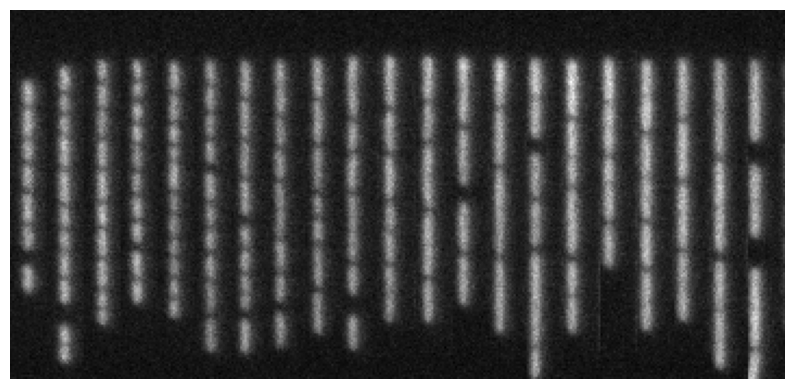

In [ ]:
# divIC example
# opLAG1_id = 287.0
channels = ['mCherry']
experiment_number = 0
file_index = 934
file_trench_index = 2
time_indices = np.arange(0, 61, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

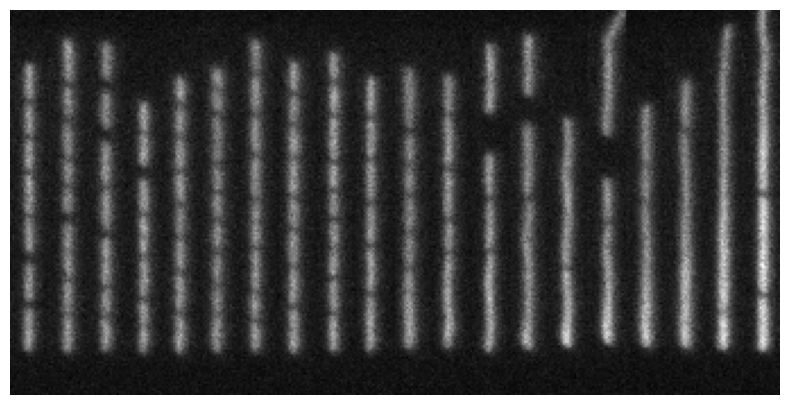

In [ ]:
# ykpC example
#opLAG1_id = 3979.
channels = ['mCherry']
experiment_number = 1
file_index = 112
file_trench_index = 2
time_indices = np.arange(7, 67, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

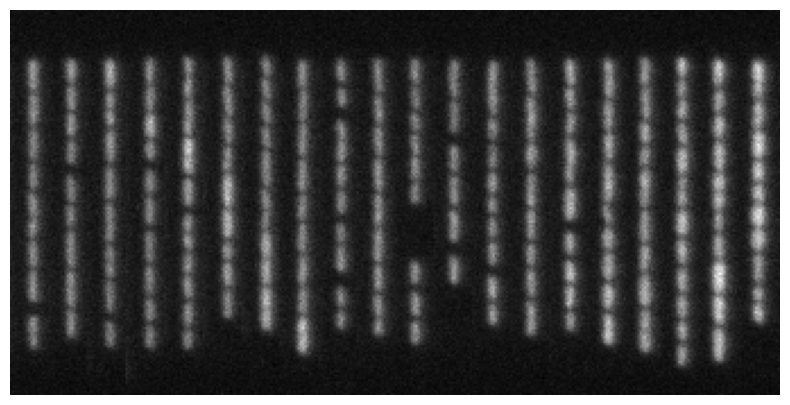

In [ ]:
# cdaR example
# opLAG1_id = 322.0	
channels = ['mCherry']
experiment_number = 1
file_index = 268
file_trench_index = 146
time_indices = np.arange(7, 67, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

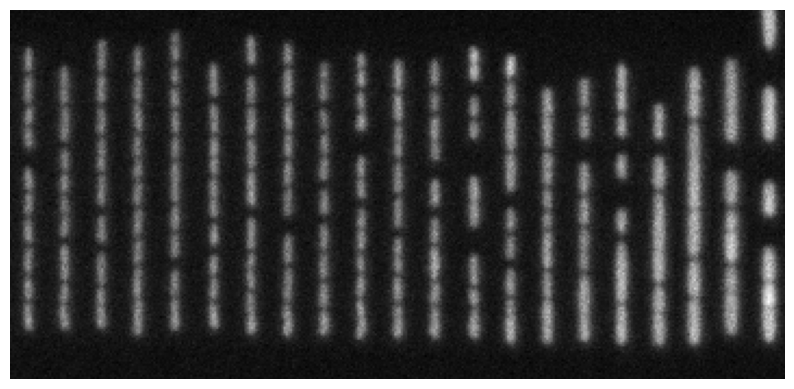

In [ ]:
# murG example
# opLAG1_id = 2244
channels = ['mCherry']
experiment_number = 0
file_index = 1002
file_trench_index = 101
time_indices = np.arange(0, 61, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

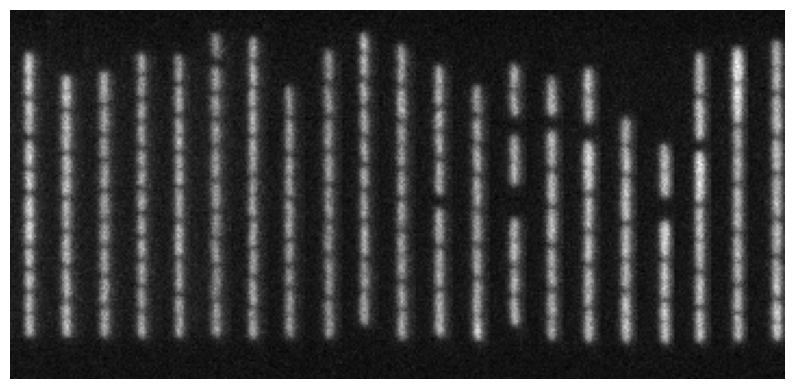

In [59]:
# mrpD example
# opLAG1_id = 4968
channels = ['mCherry']
experiment_number = 0
file_index = 246
file_trench_index = 65
time_indices = np.arange(0, 61, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

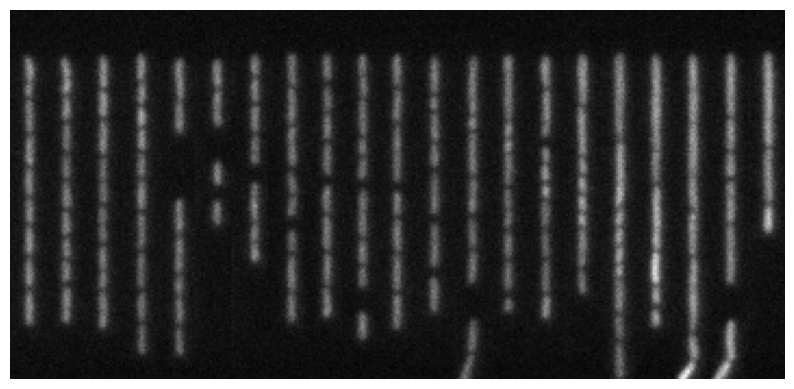

In [41]:
# parE example
channels = ['mCherry']
experiment_number = 0
file_index = 1587
file_trench_index = 127
time_indices = np.arange(0, 61, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

In [ ]:
cols = ['opLAG1_id', 'Experiment #','File Index', 'File Trench Index', 'Gene', 'Category', 'Predicted_Efficacy']
opLAG1_id = 7191.0
df_bar_per_trench.loc[df_bar_per_trench['opLAG1_id'] == opLAG1_id, cols].head(5)

,opLAG1_id,Experiment #,File Index,File Trench Index,Gene,Category,Predicted_Efficacy
Multi-Experiment Phenotype Trenchid,,,,,,,
100269373,7191.0,1,1807,130,minD,nonessential,1.0
100478216,7191.0,1,3209,75,minD,nonessential,1.0
100522303,7191.0,1,3505,58,minD,nonessential,1.0


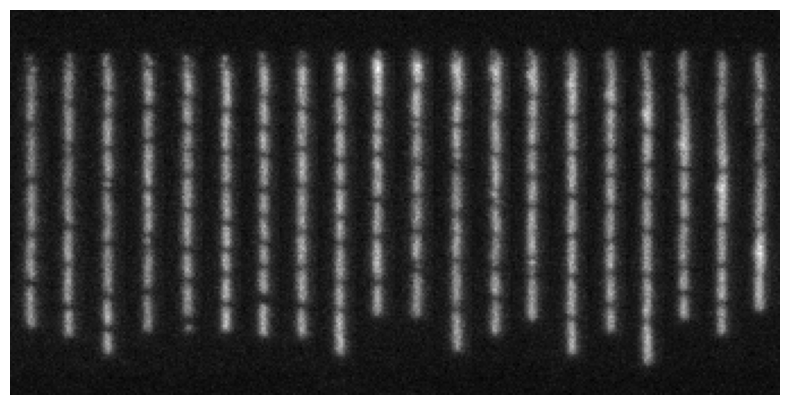

In [56]:
# parE example
channels = ['mCherry']
experiment_number = 1
file_index = 3209
file_trench_index = 75
time_indices = np.arange(7, 67, 3)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")

In [57]:
df_bar_per_trench = df_bar_per_trench_8
experiment_number =1
file_index = 3
file_trench_index = 127
df_bar_per_trench.loc[(df_bar_per_trench['Experiment #'] == experiment_number) &
                     (df_bar_per_trench['File Index'] == file_index) &
                     (df_bar_per_trench['File Trench Index'] == file_trench_index), cols]

,opLAG1_id,Experiment #,File Index,File Trench Index,Gene,Category,Predicted_Efficacy
Multi-Experiment Phenotype Trenchid,,,,,,,


In [51]:

df_bar_per_trench = df_bar_per_trench_10

In [52]:
cols = ['opLAG1_id', 'Experiment #','File Index', 'File Trench Index', 'Gene', 'Category', 'Predicted_Efficacy']
opLAG1_id = 7191.0
df_bar_per_trench.loc[df_bar_per_trench['opLAG1_id'] == opLAG1_id, cols].head(5)

,opLAG1_id,Experiment #,File Index,File Trench Index,Gene,Category,Predicted_Efficacy
Multi-Experiment Phenotype Trenchid,,,,,,,
100269373,7191.0,1,1807,130,minD,nonessential,1.0
100478216,7191.0,1,3209,75,minD,nonessential,1.0
100522303,7191.0,1,3505,58,minD,nonessential,1.0


## Lookup flagella

In [76]:
df_bar_per_trench = df_bar_per_trench_10

cols = ['opLAG1_id', 'Experiment #','File Index', 'File Trench Index', 'Gene', 'Category', 'Predicted_Efficacy']
opLAG1_id = 9235.0
df_bar_per_trench.loc[df_bar_per_trench['opLAG1_id'] == opLAG1_id, cols].head(5)

,opLAG1_id,Experiment #,File Index,File Trench Index,Gene,Category,Predicted_Efficacy
Multi-Experiment Phenotype Trenchid,,,,,,,
100012543,9235.0,1,84,27,degS,nonessential,1.0
100018624,9235.0,1,124,148,degS,nonessential,1.0
100039549,9235.0,1,265,64,degS,nonessential,1.0
100046332,9235.0,1,310,142,degS,nonessential,1.0
100054396,9235.0,1,365,11,degS,nonessential,1.0


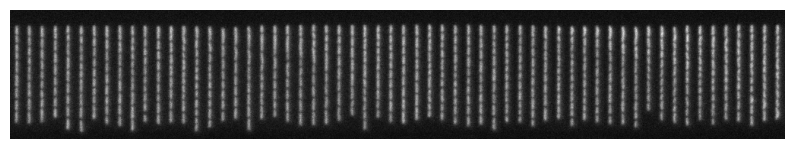

In [80]:
# parE example
channels = ['mCherry']
experiment_number = 1
file_index = 365
file_trench_index = 11
time_indices = np.arange(7, 67, 1)

plot_kymograph(indices=time_indices,
               channels=channels,
               trench_index=file_trench_index,
               kymo_index=file_index,
               headpath=headpaths[experiment_number],
               subfolder = "kymograph",
               prefix = "kymograph",
               cmap = "gray")